# Interpolation to stations: IFS-HRES 2 m temperature

This example illustrates {func}`~grid_process.grid_interp.interp2poi` with three methods:

- `nearest`: value of the nearest grid point;
- `temp`: altitude-aware interpolation designed for temperature. It fits a local sounding on the `k`
  nearest grid points (with a distance penalizing altitude differences by `z_fact`) and evaluates it at
  the station altitude;
- `temp_fixgrad`: among the grid points within `r_search` grid spacings, the one with the most similar
  altitude, corrected for the remaining altitude difference with a fixed lapse rate (6 K/km by default).

The IFS-HRES 2 m temperature forecast (0.1°, about 9 km) is interpolated to 14 stations of the
MeteoSwiss automatic weather station network, and compared with their observations. They cover a wide
range of cases, from the Swiss Plateau to the peaks:

- plain: Zürich-Kloten (KLO);
- Alpine valleys: Visp (VIS), Piotta (PIO) and Davos (DAV);
- slopes and terraces: Montana (MVE), Arosa (ARO) and Gornergrat (GOR);
- peaks: Matro (MTR), Säntis (SAE), Le Moléson (MLS), Les Diablerets (DIA), Piz Martegnas (PMA),
  Titlis (TIT) and Les Attelas (ATT).

*Data: ECMWF open data, © ECMWF, CC BY 4.0. MeteoSwiss open data, CC BY 4.0, source: MeteoSwiss.*

In [1]:
import contextlib
import io
import logging
import os
import re
import time
import timeit
from collections.abc import Callable
from functools import partial
from typing import Any

# import pyproj before earthkit.data to avoid a crash at exit (earthkit-data#1202)
import pyproj  # noqa: F401  # pylint: disable=unused-import

# grid_process data model (read at import): the SwissMetNet metadata columns give the POI labels and altitudes
os.environ["GRID_PROCESS__data_model__poi__coord_from"] = "station_abbr"
os.environ["GRID_PROCESS__data_model__poi__alt_from"] = '["station_height_masl"]'

import earthkit.data as ekd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import xarray as xr
from requests.adapters import HTTPAdapter
from urllib3.util import Retry

import grid_process.grid_interp as gri
import grid_process.timeseries as tms
import grid_process.units_conv as uconv
from grid_process import data_model as dm

# from the Plateau to the peaks: plain, valleys, slopes and terraces, peaks
STATIONS = ["KLO", "VIS", "PIO", "DAV", "MVE", "ARO", "GOR", "MTR", "SAE", "MLS", "DIA", "PMA", "TIT", "ATT"]
METHODS: dict[str, dict[str, Any]] = {
    "nearest": {"method": "nearest"},
    "temp": {"method": "temp", "z_fact": 15, "k": 50, "weight_power": 0.75},
    "temp_fixgrad": {"method": "temp_fixgrad", "r_search": 2},
}
STEPS = list(range(0, 145, 3))  # lead times [h]
BBOX = {"latitude": slice(49.0, 44.0), "longitude": slice(4.0, 12.0)}  # Switzerland with a wide margin

## Source data

We take the oldest IFS-HRES run still available on the ECMWF open data portal, so that observations
cover a large part of the forecast. Open data only serves global fields: the download is cropped to
Switzerland with a wide margin right after loading, since `temp` uses a large neighbourhood (`k=50`).
The `temp` and `temp_fixgrad` methods need the model orography, which is the surface geopotential `z` at step 0.

In [2]:
OD_ROOT = "https://data.ecmwf.int/forecasts"

# the portal sometimes times out: retry with an increasing delay (earthkit already retries the field downloads)
session = requests.Session()
retry = Retry(total=5, backoff_factor=2, status_forcelist=[429, 500, 502, 503, 504])
session.mount("https://", HTTPAdapter(max_retries=retry))
# hide the notice about the connection limit of the portal that the ECMWF open data client logs
logging.getLogger("ecmwf.opendata.utils").addFilter(lambda record: "500 simultaneous" not in record.getMessage())


def index_url(day: str, hour: int, step: int) -> str:
    return f"{OD_ROOT}/{day}/{hour:02d}z/ifs/0p1/oper/{day}{hour:02d}0000-{step}h-oper-fc-sfc.index"


def list_days() -> list[str]:
    """Days with forecasts on the portal, oldest first."""
    return sorted(set(re.findall(r'href="/forecasts/(\d{8})/"', session.get(f"{OD_ROOT}/", timeout=30).text)))


def oldest_run(last_step: int) -> tuple[str, int]:
    """Oldest run whose first and last steps are both still on the portal (old runs are purged gradually)."""
    for day in list_days():
        for hour in (0, 6, 12, 18):
            if all(session.head(index_url(day, hour, step), timeout=30).ok for step in (0, last_step)):
                return day, hour
    raise RuntimeError("No complete run found on the open data portal")


def open_data(**request: Any) -> ekd.FieldList:
    # hide the download progress bars that earthkit always shows on stderr
    with contextlib.redirect_stderr(io.StringIO()):
        return ekd.from_source(
            "ecmwf-open-data",
            model="ifs",
            resol="0p1",
            stream="oper",
            type="fc",
            date=int(run_date),
            time=run_hour,
            **request,
        ).to_fieldlist()


run_date, run_hour = oldest_run(STEPS[-1])
RUN = f"{run_date[:4]}-{run_date[4:6]}-{run_date[6:]} {run_hour:02d} UTC"
print(f"IFS-HRES run: {RUN}")

ds = open_data(param="2t", step=STEPS).to_xarray(time_dims=["forecast_reference_time", "step"], squeeze=False)
ds = ds.squeeze(["level", "level_type"], drop=True).sel(BBOX).astype("float32").load()
ds = uconv.ds_to(ds, {"2t": "degC"})

z_surf = open_data(param="z", levtype="sfc", step=0).to_xarray()["z"].squeeze().reset_coords(drop=True).sel(BBOX)
ds = ds.assign_coords(surface_altitude=(z_surf / 9.80665).astype("float32").assign_attrs(units="m"))
ds = tms.setindex_validtime(ds)  # forecast_reference_time and step -> time
ds

IFS-HRES run: 2026-10-26 00 UTC


<xarray.Dataset> Size: 818kB
Dimensions:                  (time: 49, latitude: 51, longitude: 80)
Coordinates:
  * time                     (time) datetime64[us] 392B 2026-10-26 ... 2026-1...
    forecast_reference_time  (time) datetime64[us] 392B 2026-10-26 ... 2026-1...
  * latitude                 (latitude) float64 408B 49.0 48.9 ... 44.1 44.0
  * longitude                (longitude) float64 640B 4.1 4.2 4.3 ... 11.9 12.0
    surface_altitude         (latitude, longitude) float32 16kB 120.2 ... 394.9
Data variables:
    2t                       (time, latitude, longitude) float32 800kB 8.43 ....
Attributes:
    Conventions:  CF-1.8
    institution:  ECMWF

## Stations and observations

The station metadata provide the coordinates and the altitude used by `temp` and `temp_fixgrad`.
Instead of renaming the metadata columns, the environment variables set in the setup cell adapt the
`grid_process` data model: the `station_abbr` column becomes the `poi` coordinate of the output and
`station_height_masl` gives the altitude. Observations are the 10-minute instantaneous
2 m temperature (`tre200s0`).

In [3]:
SMN_URL = "https://data.geo.admin.ch/ch.meteoschweiz.ogd-smn"

meta = pd.read_csv(f"{SMN_URL}/ogd-smn_meta_stations.csv", sep=";", encoding="cp1252")
# all SwissMetNet stations: the interpolation and the benchmark use them all, the plots the selected STATIONS
pois_all = gpd.GeoDataFrame(
    meta[["station_abbr", "station_name", "station_height_masl"]],
    geometry=gpd.points_from_xy(meta["station_coordinates_lv95_east"], meta["station_coordinates_lv95_north"]),
    crs="EPSG:2056",
).set_index("station_abbr", drop=False)
pois = pois_all.loc[STATIONS]


def read_smn(station_abbr: str, granularity: str, periods: tuple[str, ...] = ("recent", "now")) -> pd.DataFrame:
    """Read station data files (granularity 't': 10 min, 'h': hourly); timestamps are in UTC."""
    abbr = station_abbr.lower()
    frames = [
        pd.read_csv(f"{SMN_URL}/{abbr}/ogd-smn_{abbr}_{granularity}_{period}.csv", sep=";", encoding="cp1252")
        for period in periods
    ]
    df = pd.concat(frames)
    df["time"] = pd.to_datetime(df["reference_timestamp"], format="%d.%m.%Y %H:%M")
    return df.drop_duplicates("time").set_index("time").sort_index()


t_start, t_end = ds.time.values[[0, -1]]
# regular 10 min steps, so that missing observations show as gaps in the plots
obs = pd.DataFrame({abbr: read_smn(abbr, "t")["tre200s0"] for abbr in STATIONS}).asfreq("10min")
obs = obs.loc[t_start:t_end]
pois[["station_name", "station_height_masl"]]

,station_name,station_height_masl
station_abbr,,
KLO,Zürich / Kloten,426.0
VIS,Visp,639.0
PIO,Piotta,990.0
DAV,Davos,1594.0
MVE,Montana,1423.0
ARO,Arosa,1878.0
GOR,Gornergrat,3129.0
MTR,Matro,2171.0
SAE,Säntis,2501.0


## Interpolation

Each method is called once on all lead times and all SwissMetNet stations (about 160), of which the
figure below shows the 14 selected ones. The duration of this first call is kept for the
benchmark below. On a regular grid with 1D coordinates, `nearest` and `linear` use xarray's interpolation by default (`try_reg=True`), which is efficient for large grids but may be slower for small grids with many other dimensions. They are also run through the generic path (`try_reg=False`) for comparison.

In [4]:
def with_try_reg(methods: dict[str, dict[str, Any]], data: xr.Dataset) -> dict[str, dict[str, Any]]:
    """On a grid with 1D spatial coordinates, 'nearest' and 'linear' use xarray's interpolation by default
    (try_reg=True): add the generic path (try_reg=False) to compare both."""
    regular = len(dm.get_spatial_dims(data)) == 2
    expanded: dict[str, dict[str, Any]] = {}
    for method, kw in methods.items():
        if regular and kw["method"] in ("nearest", "linear"):
            expanded[method] = kw | {"try_reg": True}
            expanded[f"{method} (try_reg=False)"] = kw | {"try_reg": False}
        else:
            expanded[method] = kw
    return expanded


runs = with_try_reg(METHODS, ds)
results: dict[str, xr.Dataset] = {}
first_call: dict[str, float] = {}
for label, kwargs in runs.items():
    t0 = time.perf_counter()
    results[label] = gri.interp2poi(ds, pois_all, **kwargs)
    first_call[label] = time.perf_counter() - t0
for label in METHODS:
    if f"{label} (try_reg=False)" in results:
        diff = abs(results[label]["2t"] - results[f"{label} (try_reg=False)"]["2t"])
        print(
            f"{label}, try_reg=True vs. False: mean abs. difference {diff.mean().item():.3g} °C,"
            f" max. {diff.max().item():.3g} °C"
        )

# model altitude at the nearest grid point, to compare with the station altitude
model_alt = gri.interp2poi(ds["surface_altitude"].reset_coords(drop=True).to_dataset(name="alt"), pois, "nearest")
results["temp"]

nearest, try_reg=True vs. False: mean abs. difference 0 °C, max. 0 °C


<xarray.Dataset> Size: 34kB
Dimensions:                  (poi: 159, time: 49)
Coordinates:
  * poi                      (poi) <U3 2kB 'ABO' 'AEG' 'AIG' ... 'WYN' 'ZER'
  * time                     (time) datetime64[us] 392B 2026-10-26 ... 2026-1...
    forecast_reference_time  (time) datetime64[us] 392B 2026-10-26 ... 2026-1...
Data variables:
    2t                       (poi, time) float32 31kB 1.94 -0.08955 ... 4.12
Attributes:
    institution:  ECMWF

## Visual comparison

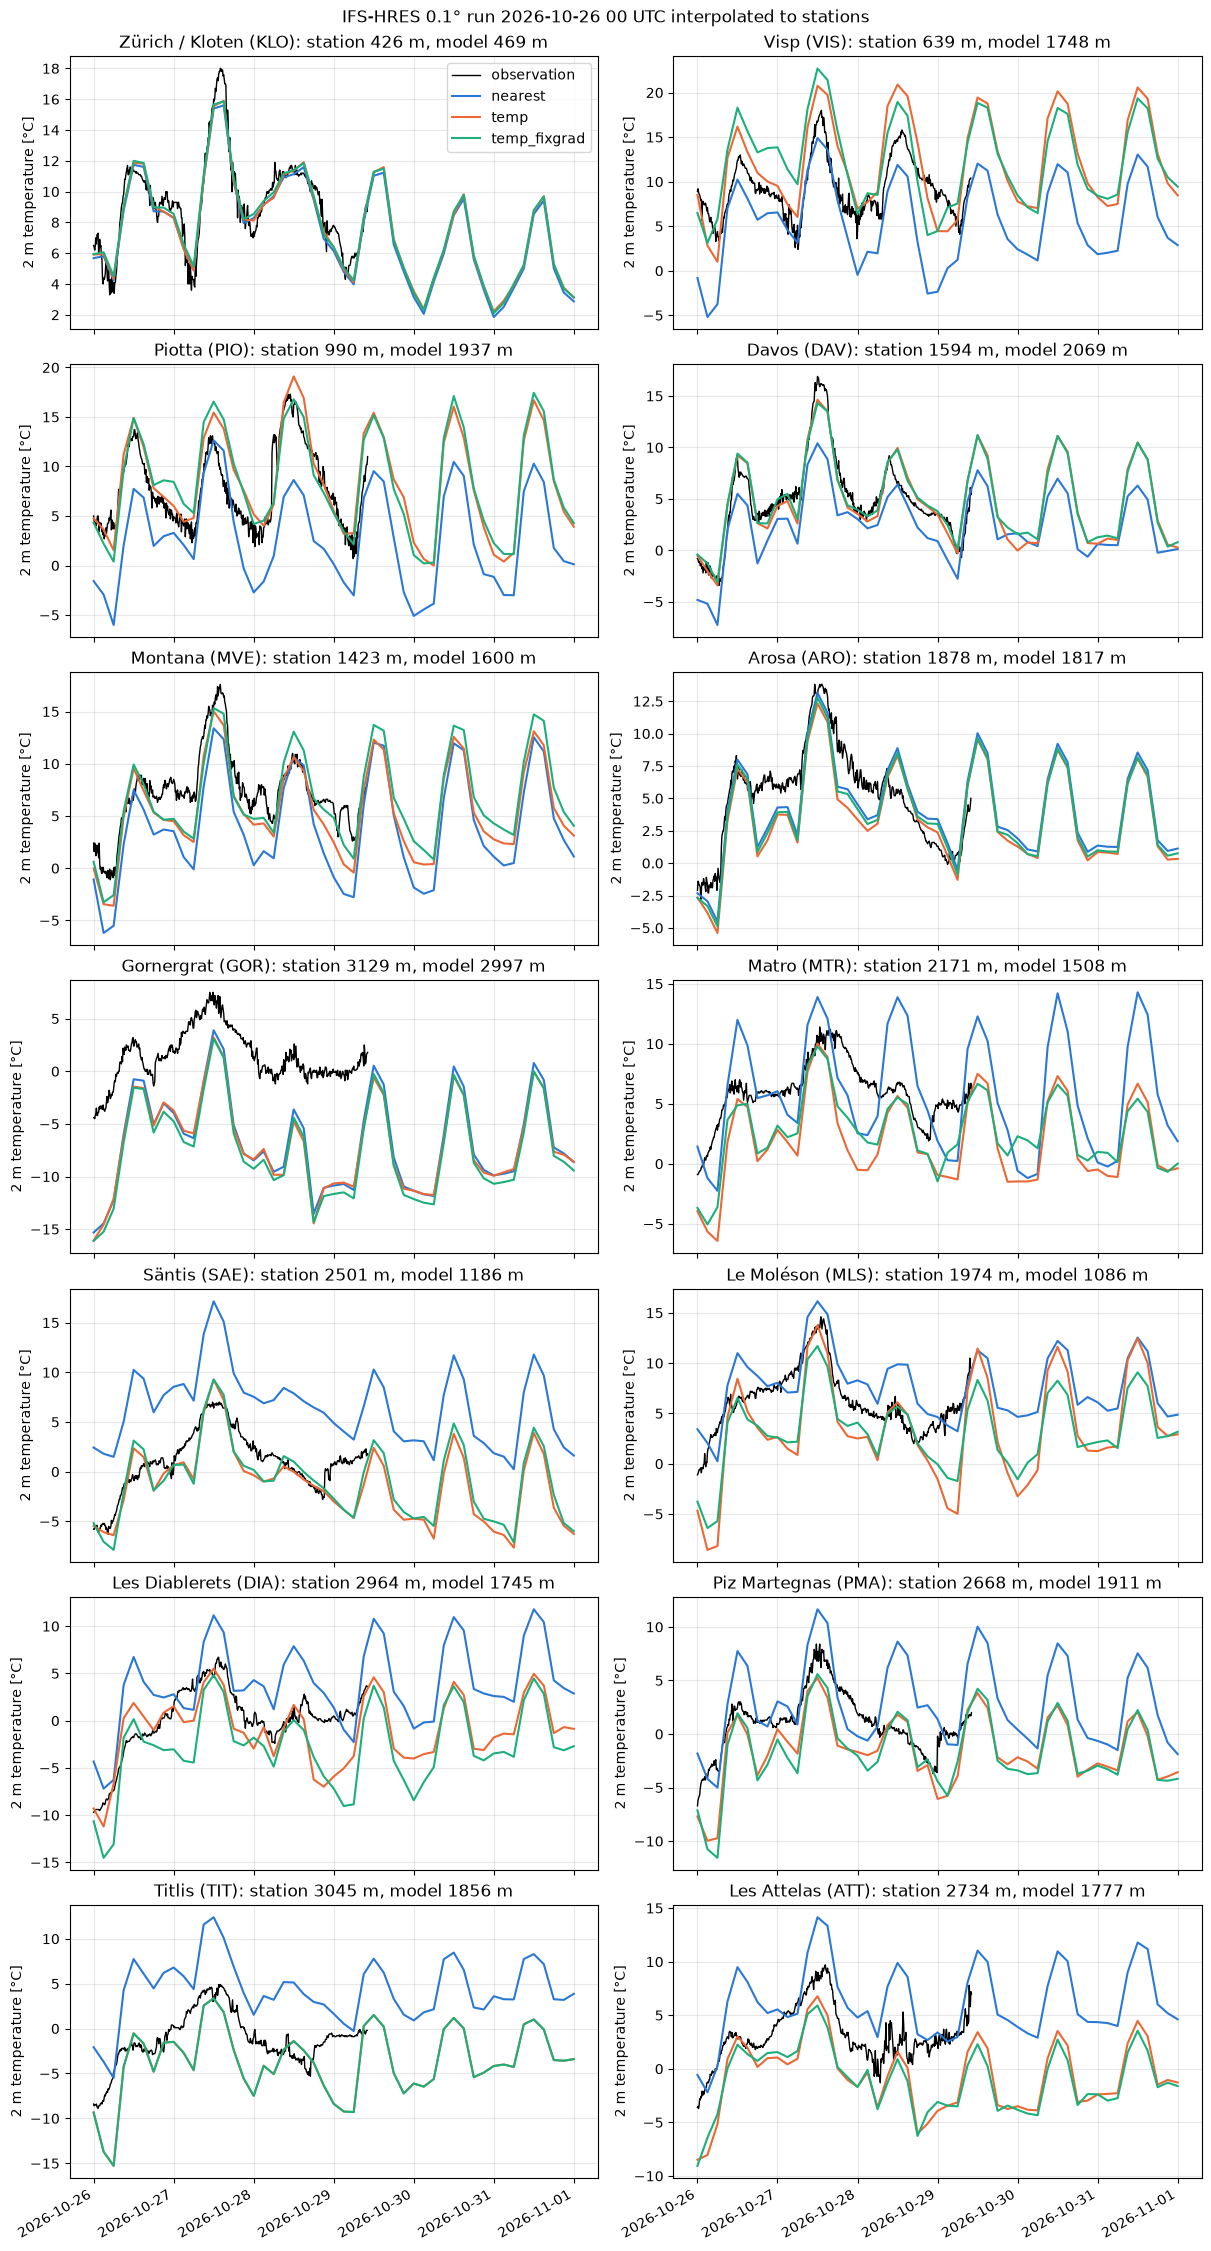

In [5]:
COLORS = {"nearest": "#2a78d6", "temp": "#eb6834", "temp_fixgrad": "#1baf7a"}

nrows = (len(STATIONS) + 1) // 2
fig, axes = plt.subplots(nrows, 2, figsize=(12, 3.2 * nrows), sharex=True, layout="constrained")
for ax, station in zip(axes.flat, STATIONS):
    ax.plot(obs.index, obs[station], color="black", lw=1, label="observation")
    for label in METHODS:
        res = results[label]
        ax.plot(res.time, res["2t"].sel(poi=station), color=COLORS[label], lw=1.5, label=label)
    info = pois.loc[station]
    ax.set_title(
        f"{info.station_name} ({station}): station {info.station_height_masl:.0f} m, "
        f"model {model_alt['alt'].sel(poi=station).item():.0f} m"
    )
    ax.set_ylabel("2 m temperature [°C]")
    ax.grid(alpha=0.3)
axes[0, 0].legend()
fig.suptitle(f"IFS-HRES 0.1° run {RUN} interpolated to stations")
fig.autofmt_xdate()
plt.show()

## Performance benchmark

The first call includes building the neighbour search structures, which `grid_process` caches.
Subsequent calls on the same grid and stations (e.g. for other variables or runs) reuse them: their
runtime is the mean ± standard deviation over 5 repetitions. All SwissMetNet stations are used, which is
closer to an operational use than the 14 stations of the figure.

In [6]:
def benchmark(
    func: Callable[..., xr.Dataset],
    data: xr.Dataset,
    target: gpd.GeoDataFrame | xr.Dataset,
    methods: dict[str, dict[str, Any]],
    first_call_times: dict[str, float],
    repeat: int = 5,
) -> pd.DataFrame:
    """Runtime of the first call and mean ± standard deviation of the subsequent calls of each method."""
    rows: dict[str, dict[str, Any]] = {}
    for method, kw in methods.items():
        times = np.array(timeit.repeat(partial(func, data, target, **kw), number=1, repeat=repeat))
        rows[method] = {
            "first call [s]": f"{first_call_times[method]:.3f}",
            "subsequent calls [s]": f"{times.mean():.3f} ± {times.std():.3f}",
        }
    return pd.DataFrame.from_dict(rows, orient="index").rename_axis("method")


print(f"{ds.latitude.size * ds.longitude.size} grid points × {ds.time.size} lead times -> {len(pois_all)} stations")
benchmark(gri.interp2poi, ds, pois_all, runs, first_call)

4080 grid points × 49 lead times -> 159 stations


,first call [s],subsequent calls [s]
method,,
nearest,0.037,0.004 ± 0.001
nearest (try_reg=False),0.010,0.007 ± 0.000
temp,0.023,0.011 ± 0.000
temp_fixgrad,0.027,0.007 ± 0.001


## Takeaways

- In complex terrain the nearest grid point of a 9 km model is often far from the station altitude:
  about 1000 m above it in the valleys of Visp and Piotta, and 700 to 1300 m below it on the peaks.
  `nearest` then inherits a large altitude-related bias: too cold in the valleys and too warm on the
  peaks.
- `temp` and `temp_fixgrad` remove most of this bias, with similar results in most cases. The correction
  works best at Piotta, Davos, Säntis, Les Diablerets and Piz Martegnas.
- The correction is only as good as the lapse rate it assumes: `temp` uses the local vertical profile of
  the model, `temp_fixgrad` a fixed lapse rate. On peaks such as Titlis, Les Attelas, Le Moléson or Matro,
  both are at times too cold, especially at night, when the summit is warmer than the lapse rate implies.
  In the valley of Visp they overshoot the daily maxima.
- Where the model altitude is close to the station altitude (Kloten, Montana, Arosa, Gornergrat), the
  three methods agree. The large difference to the observations at Gornergrat comes from the model
  itself, not from the interpolation.
- For all SwissMetNet stations, each method takes a few hundredths of a second at most, first call
  included. `temp` fits one sounding per station: it is the slowest of the subsequent calls, and becomes
  the most expensive method for thousands of points.
- On the regular IFS grid, `nearest` gives the same values with the default regular path
  (`try_reg=True`, xarray's interpolation) and with the generic path (`try_reg=False`).